# 06 Decomposition

A decomposition splits a series into a slow trend, a repeating seasonal pattern and what is left over. We start
with the weekly season, because the plots in 03 show it is the strongest, and then look at the yearly one. We also
check whether the weekly pattern is additive (a fixed number of extra units on Saturdays) or multiplicative (a
fixed percentage), because that decides which kind of Holt-Winters we fit.

## Load

In [1]:
import sys
sys.path.append("../src")
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller

from config import ROOT, INTERIM, TABLES, FIGS, CATEGORIES, FIG_STYLE
from stationarity import swing_rule, fix_christmas

plt.rcParams.update(FIG_STYLE)
written = []
df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                for c in ["foods", "hobbies", "household"]], ignore_index=True)
df["category"] = df["item_id"].str.split("_").str[0]
totals = {cat: df[df["category"] == cat].groupby("date")["sales"].sum() for cat in CATEGORIES}
totals["CA_TOTAL"] = df.groupby("date")["sales"].sum()
EXAMPLES = ["FOODS_1_043", "FOODS_1_085", "HOBBIES_1_004", "HOBBIES_1_005", "HOUSEHOLD_1_019", "HOUSEHOLD_1_040"]

## A first decomposition: the best seller

This is the first decomposition we ran, on the top FOODS seller with a 7-day period, before we had thought about
any of the choices below.

ADF statistic: -4.2792, p-value: 0.0005


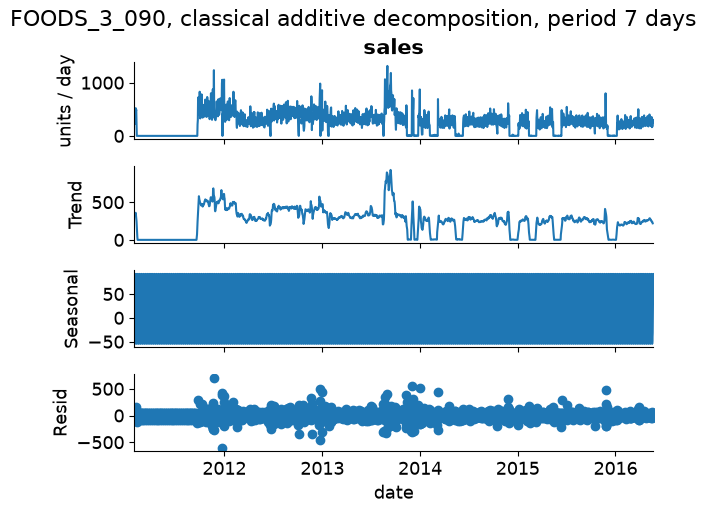

In [2]:
ts = df[df["item_id"] == "FOODS_3_090"].set_index("date")["sales"]
res = adfuller(ts)
print(f"ADF statistic: {res[0]:.4f}, p-value: {res[1]:.4f}")
fig = seasonal_decompose(ts, model="additive", period=7).plot()
fig.suptitle("FOODS_3_090, classical additive decomposition, period 7 days", y=1.02)
fig.axes[-1].set_xlabel("date")
fig.axes[0].set_ylabel("units / day")
plt.savefig(FIGS / "sample_decomposition.png", bbox_inches="tight")
written.append(FIGS / "sample_decomposition.png")
plt.show()

## Additive or multiplicative?

Our rule: if the weekly swing (highest minus lowest day of each week) grows with the weekly level, the season scales
with the level and multiplicative fits better. We call that a Spearman correlation of at least 0.5 with p below
0.05. We also compare how much is left in the residual under each form.

A multiplicative model divides by the level, so a single zero breaks it. For single products we add 1 to every
day. The totals are almost never zero, except on 25 December when the stores close; for the decomposition only, we
replace that day with the same weekday one week before and after.

In [3]:
def residual_spread(y, kind):
    """Residual sd (in units) divided by the mean, for one decomposition."""
    if kind == "stl":
        r = STL(y, period=7, robust=True).fit()
        resid = y - r.trend - r.seasonal
    else:
        d = seasonal_decompose(y, model=kind, period=7)
        fit = d.trend + d.seasonal if kind == "additive" else d.trend * d.seasonal
        resid = y - fit
    return float(np.nanstd(resid) / np.mean(y))

choice = []
for name, s in list(totals.items()) + [(i, df[df["item_id"] == i].set_index("date")["sales"]) for i in EXAMPLES]:
    is_total = name in totals
    y = fix_christmas(s) if is_total else s + 1.0          # totals: Christmas fixed; items: +1 so division works
    rho, p, pick = swing_rule(y.index, y.to_numpy())
    choice.append({"series": name, "level": "total" if is_total else "item", "zero_handling": "Christmas replaced" if is_total else "sales + 1",
                   "zero_days": int((s == 0).sum()), "spearman_level_vs_swing": rho, "p_value": p, "rule_choice": pick,
                   "resid_cv_additive": residual_spread(y, "additive"), "resid_cv_multiplicative": residual_spread(y, "multiplicative"),
                   "resid_cv_stl": residual_spread(y, "stl")})
choice = pd.DataFrame(choice)
choice["lower_residual"] = np.where(choice["resid_cv_multiplicative"] < choice["resid_cv_additive"], "multiplicative", "additive")
choice.to_csv(TABLES / "decomposition_choice.csv", index=False)
written.append(TABLES / "decomposition_choice.csv")
choice.round(4)

,series,level,zero_handling,zero_days,spearman_level_vs_swing,p_value,rule_choice,resid_cv_additive,resid_cv_multiplicative,resid_cv_stl,lower_residual
0,FOODS,total,Christmas replaced,0,0.3318,0.0000,additive,0.0710,0.0698,0.0709,multiplicative
1,HOBBIES,total,Christmas replaced,5,0.2086,0.0005,additive,0.1182,0.1179,0.1167,multiplicative
2,HOUSEHOLD,total,Christmas replaced,5,0.6179,0.0000,multiplicative,0.0855,0.0763,0.0754,multiplicative
3,CA_TOTAL,total,Christmas replaced,0,0.3571,0.0000,additive,0.0664,0.0648,0.0644,multiplicative
4,FOODS_1_043,item,sales + 1,117,0.5740,0.0000,multiplicative,0.3085,0.3022,0.3424,multiplicative
5,FOODS_1_085,item,sales + 1,12,0.5351,0.0000,multiplicative,0.2664,0.2612,0.2631,multiplicative
6,HOBBIES_1_004,item,sales + 1,23,0.3715,0.0000,additive,0.3769,0.3740,0.3440,multiplicative
7,HOBBIES_1_005,item,sales + 1,193,0.6390,0.0000,multiplicative,0.4183,0.4162,0.4151,multiplicative
8,HOUSEHOLD_1_019,item,sales + 1,24,0.4188,0.0000,additive,0.3104,0.3079,0.3015,multiplicative
9,HOUSEHOLD_1_040,item,sales + 1,100,0.5554,0.0000,multiplicative,0.3644,0.3603,0.3577,multiplicative


## Weekly decomposition: a total and a product

The last 52 weeks, three ways: classical additive, classical multiplicative and STL.

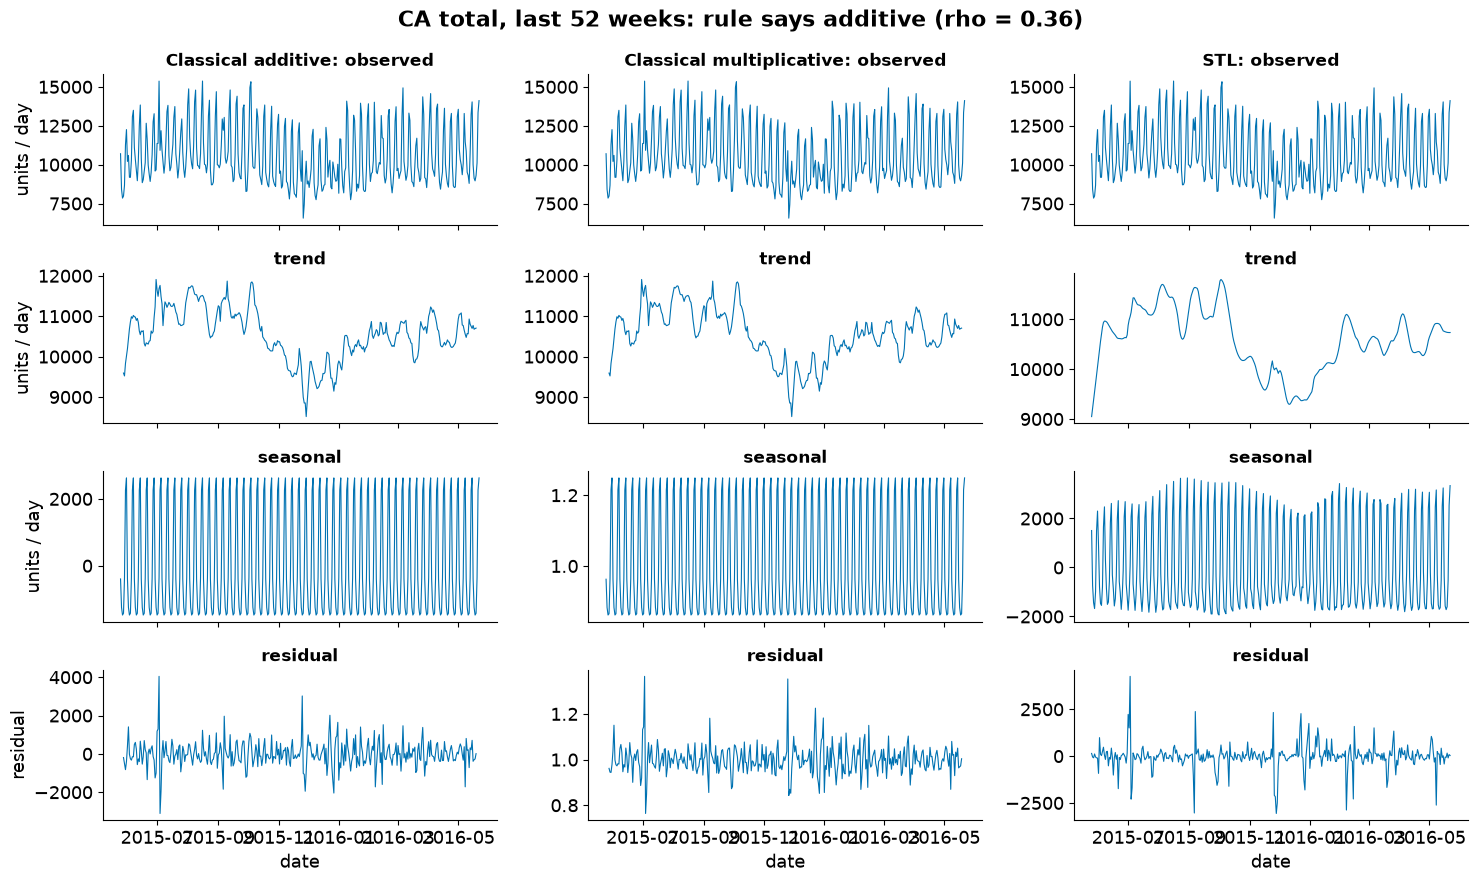

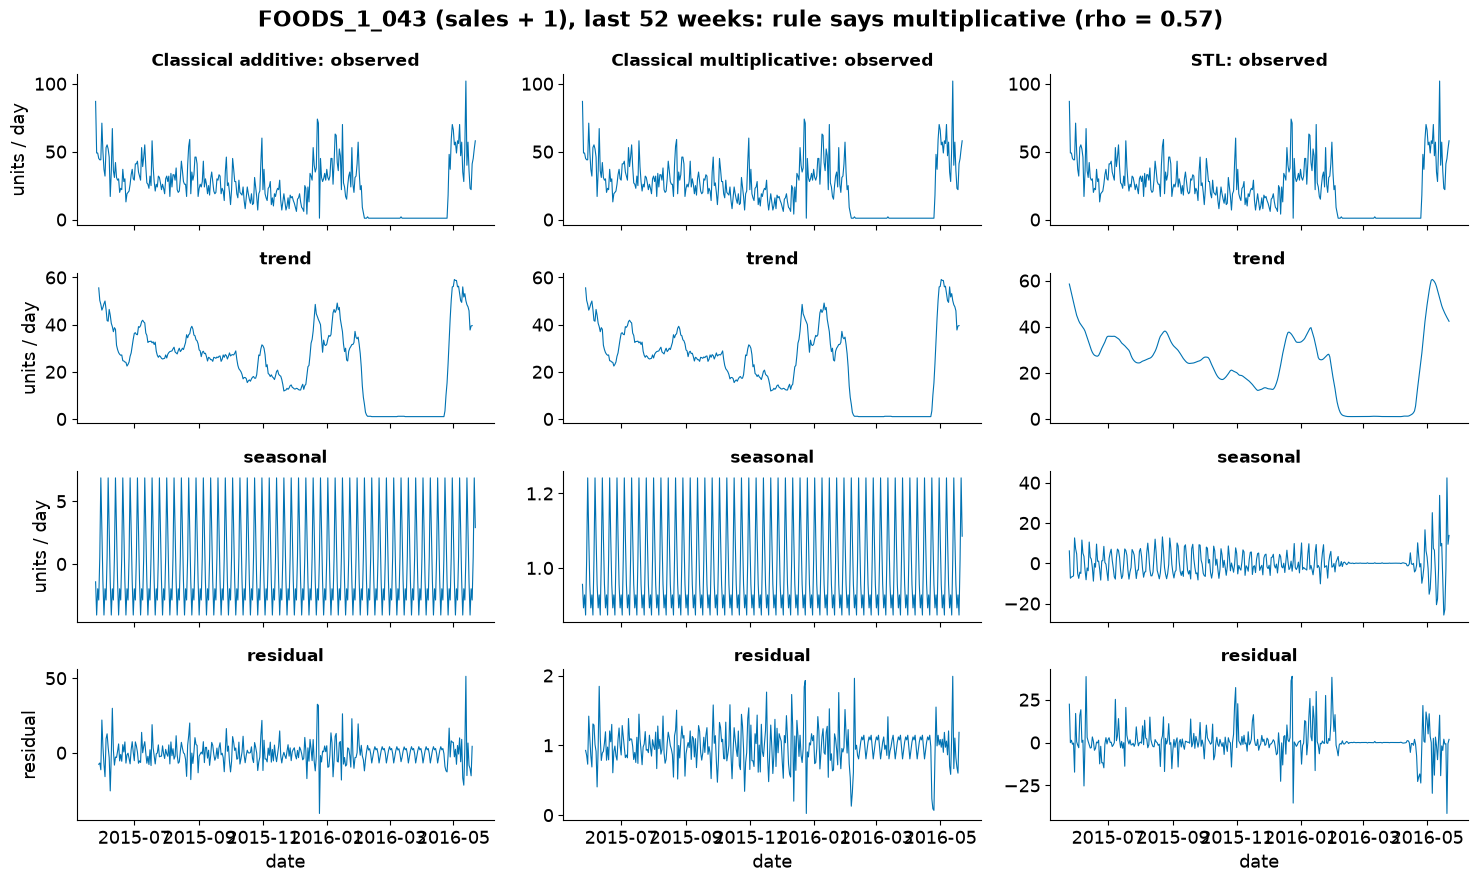

In [4]:
def decomp_figure(y, fname, title):
    y = y.iloc[-364:]
    add = seasonal_decompose(y, model="additive", period=7)
    mul = seasonal_decompose(y, model="multiplicative", period=7)
    stl = STL(y, period=7, robust=True).fit()
    fig, axes = plt.subplots(4, 3, figsize=(15, 9), sharex=True)
    for col, (lab, parts) in enumerate([("Classical additive", [add.observed, add.trend, add.seasonal, add.resid]),
                                        ("Classical multiplicative", [mul.observed, mul.trend, mul.seasonal, mul.resid]),
                                        ("STL", [y, stl.trend, stl.seasonal, stl.resid])]):
        for row, (part, z) in enumerate(zip(["observed", "trend", "seasonal", "residual"], parts)):
            axes[row, col].plot(z.index, z, lw=0.8, color="#0072B2")
            axes[row, col].set_title(f"{lab}: {part}" if row == 0 else part, fontsize=12)
        axes[-1, col].set_xlabel("date")
    for row in range(4):
        axes[row, 0].set_ylabel("units / day" if row < 3 else "residual")
    fig.suptitle(title, fontsize=16, fontweight="bold")
    fig.tight_layout()
    fig.savefig(FIGS / fname)
    written.append(FIGS / fname)
    plt.show()

c = choice.set_index("series")
decomp_figure(fix_christmas(totals["CA_TOTAL"]), "decomposition_aggregate.png",
              f"CA total, last 52 weeks: rule says {c.loc['CA_TOTAL', 'rule_choice']} (rho = {c.loc['CA_TOTAL', 'spearman_level_vs_swing']:.2f})")
e0 = EXAMPLES[0]
decomp_figure(df[df["item_id"] == e0].set_index("date")["sales"] + 1.0, "decomposition_item.png",
              f"{e0} (sales + 1), last 52 weeks: rule says {c.loc[e0, 'rule_choice']} (rho = {c.loc[e0, 'spearman_level_vs_swing']:.2f})")

## The yearly season

The weekly pattern is easy to see in daily data. For the yearly one we add the days into weeks and decompose with a
period of 52 weeks, using STL so a few odd weeks cannot pull the season around.

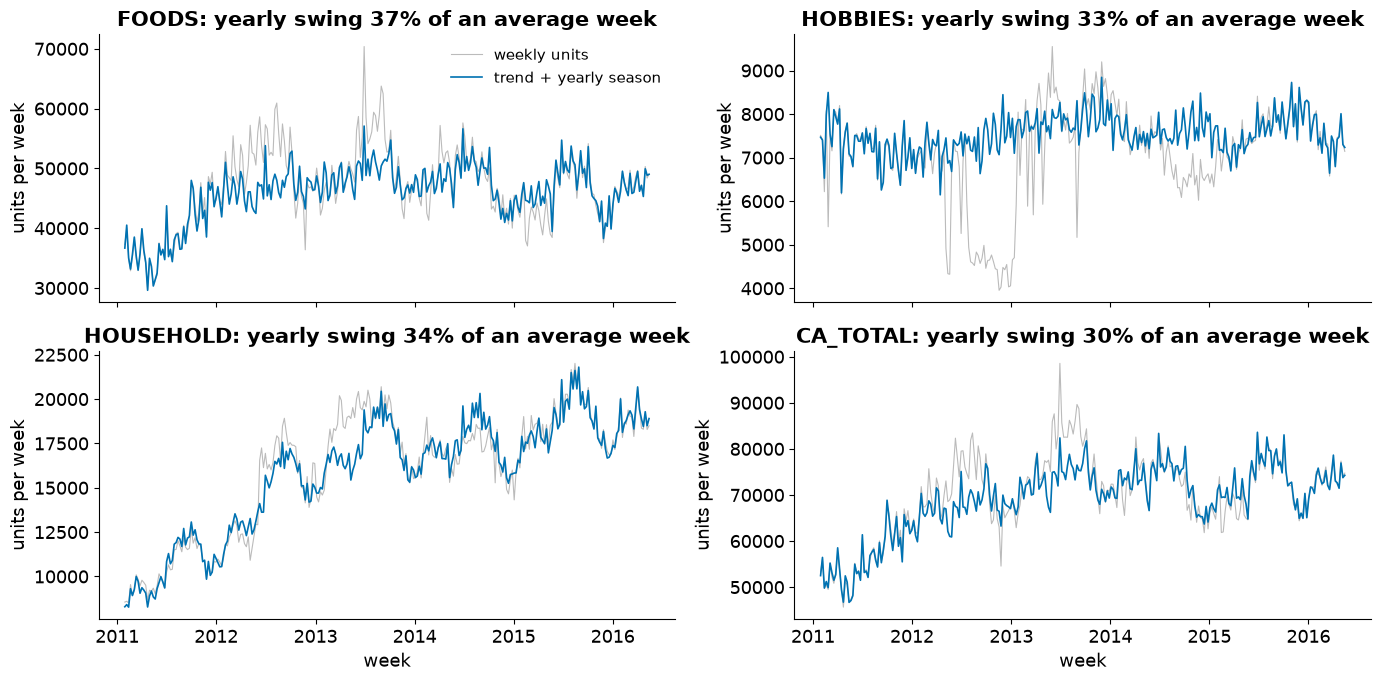

,series,yearly_swing_share_of_mean,yearly_p10_p90_share_of_mean,peak_month,low_month,weekly_swing_share_of_mean
0,FOODS,0.372,0.163,6,11,0.371
1,HOBBIES,0.330,0.138,12,4,0.302
2,HOUSEHOLD,0.341,0.202,8,12,0.457
3,CA_TOTAL,0.300,0.151,8,12,0.372


In [5]:
def weekly(s):
    """Full Saturday-to-Friday weeks only."""
    w = s.groupby(s.index - pd.to_timedelta((s.index.dayofweek - 5) % 7, unit="D")).agg(["sum", "size"])
    return w[w["size"] == 7]["sum"]

yearly = []
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for ax, (name, s) in zip(axes.flat, totals.items()):
    w = weekly(fix_christmas(s))
    r = STL(w, period=52, robust=True).fit()
    ax.plot(w.index, w, color="#BBBBBB", lw=0.8, label="weekly units")
    ax.plot(w.index, r.trend + r.seasonal, color="#0072B2", lw=1.2, label="trend + yearly season")
    swing = (r.seasonal.max() - r.seasonal.min()) / w.mean()
    ax.set_title(f"{name}: yearly swing {swing:.0%} of an average week")
    ax.set_ylabel("units per week")
    sea = r.seasonal / w.mean()
    # the peak-to-trough swing is set by a few holiday weeks, so we also give the 10th-90th percentile range
    yearly.append({"series": name, "yearly_swing_share_of_mean": swing,
                   "yearly_p10_p90_share_of_mean": sea.quantile(0.9) - sea.quantile(0.1),
                   "peak_month": int(r.seasonal.groupby(r.seasonal.index.month).mean().idxmax()),
                   "low_month": int(r.seasonal.groupby(r.seasonal.index.month).mean().idxmin())})
for ax in axes[-1]:
    ax.set_xlabel("week")
axes[0, 0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "yearly_seasonality.png")
written.append(FIGS / "yearly_seasonality.png")
plt.show()

# the weekly swing, for comparison: highest minus lowest weekday mean, divided by the mean day
weekly_swing = {k: (s.groupby(s.index.dayofweek).mean().max() - s.groupby(s.index.dayofweek).mean().min()) / s.mean()
                for k, s in totals.items()}
yearly = pd.DataFrame(yearly).assign(weekly_swing_share_of_mean=lambda x: x["series"].map(weekly_swing))
yearly.round(3)

## What we found

The weekly decomposition does what we hoped: once the weekly pattern is taken out, the trend of the totals is
smooth and the residual is small (its spread is about 7% of the mean for the California total, and 27-42% for
single products, which are much noisier).

Additive or multiplicative turned out to matter less than we expected. Our rule picks additive for FOODS, HOBBIES
and the California total, and multiplicative for HOUSEHOLD and for 4 of the 6 example products. But the residual
spread hardly differs between the two forms (0.066 against 0.065 for the California total), and STL is about the
same again. So in notebook 07 we fit the additive Holt-Winters, which is the simpler of the two and needs no
fix for zero days.

The yearly season surprised us. Measured on weekly totals with STL, it swings from peak to trough by 30-37% of an
average week, about as much as the weekly swing within a week (30-46%). Looking closer, that peak-to-trough number
is set by a handful of weeks: the weeks from Thanksgiving to Christmas are 11-13% below normal and a few weeks in
late June about 15% above. The typical yearly movement (10th to 90th percentile) is 14-20%, and every single week
still has the full weekly swing. HOBBIES is the odd one out, peaking in December, which fits gifts.

This also corrects the monthly plot in 03: those monthly averages mix in the growth of the totals over five years
(2016 only contributes January to May, at a higher level), which is why HOBBIES looked highest in June there. STL
takes the trend out first, so its yearly picture is the one to trust.

For forecasting 28 days ahead, the weekly season is the part every model must get right. A yearly term would help
mostly around the November-December dip, which falls inside our first test window.

## What comes next

`07a_classical_forecasting` uses all of this: a weekly season in every model, the differencing that 05 recommends, and an additive Holt-Winters.

In [6]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\figures\sample_decomposition.png 92 KB
outputs\tables\decomposition_choice.csv 2 KB
outputs\figures\decomposition_aggregate.png 540 KB
outputs\figures\decomposition_item.png 454 KB
outputs\figures\yearly_seasonality.png 345 KB
